# 🎓 Capstone Project: REFERENCE SOLUTION
### "What is this market data telling us?"

> **How to use this notebook.** Open it *after* you've finished your own analysis. Don't compare answers line by line; compare **approaches** and **judgement calls**.
> There is no single right analysis, but there are better and worse *evidence*, *honesty* and *explanations*. Every number below is computed in code.

**Memo to the head of analytics: summary** (details and evidence follow)

The notebook is organised exactly like the rubric: **1** overview · **2** data quality & cleaning · **3** descriptive statistics · **4** visualisations · **5** correlation analysis · **6** observations & hypotheses · **7** ML-readiness.

In [1]:
import sys; sys.path.insert(0, "..")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from course_utils import DATA_DIR, first_look

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 100})
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 140)

prices_raw = pd.read_csv(DATA_DIR / "market_prices_raw.csv")
production_raw = pd.read_excel(DATA_DIR / "production_by_county.xlsx", sheet_name="production", skiprows=2)
counties = pd.read_excel(DATA_DIR / "production_by_county.xlsx", sheet_name="counties")
weather = pd.read_json(DATA_DIR / "weather_monthly.json")
with open(DATA_DIR / "markets.json") as f:
    markets = pd.json_normalize(json.load(f))
markets.columns = markets.columns.str.replace(".", "_", regex=False)

def md(text):
    display(Markdown(text))

---
# 1 · Dataset overview

In [2]:
first_look(prices_raw, n=3)

📐 Shape: 15,093 rows × 9 columns
🔁 Fully duplicated rows: 45


,dtype,missing,missing_%,unique
record_id,str,0,0.0,15048
date,str,0,0.0,209
recorded_at,str,0,0.0,13401
crop,str,0,0.0,8
market,str,0,0.0,10
county,str,0,0.0,46
price_kes_per_kg,float64,353,2.3,1742
price_unit,str,0,0.0,2
volume_kg,float64,407,2.7,4205


,record_id,date,recorded_at,crop,market,county,price_kes_per_kg,price_unit,volume_kg
0,R012281,2024-04-08,2024-04-08 07:51:00,Cabbage,Machakos Market,Machakos,40.8,KES/kg,10520.0
1,R008502,2023-04-10,2023-04-10 07:46:00,Potatoes,City Market,Nairobi,64.3,KES/kg,19790.0
2,R014632,2024-11-25,2024-11-25 09:35:00,Beans,Karatina Market,Nyeri,168.1,KES/kg,14540.0


In [3]:
overview = pd.DataFrame([
    ("prices_raw",      prices_raw.shape[0], prices_raw.shape[1], "one price observation: a crop at a market on a Monday", "2021-01-04 → 2024-12-30", "record_id (should be unique)"),
    ("production_raw",  production_raw.shape[0], production_raw.shape[1], "one county × crop × year production figure", "2021–2024", "county, crop, year"),
    ("counties",        counties.shape[0], counties.shape[1], "one county with its region and 2019 population", "static", "county"),
    ("markets",         markets.shape[0], markets.shape[1], "one market with type, coordinates and crops traded", "static", "market"),
    ("weather",         weather.shape[0], weather.shape[1], "one county × month rainfall and temperature", "2021-01 → 2024-12", "county, year, month"),
], columns=["table", "rows", "columns", "one row is…", "period", "key"])
overview

,table,rows,columns,one row is…,period,key
0,prices_raw,15093,9,one price observation: a crop at a market on a...,2021-01-04 → 2024-12-30,record_id (should be unique)
1,production_raw,204,5,one county × crop × year production figure,2021–2024,"county, crop, year"
2,counties,9,3,one county with its region and 2019 population,static,county
3,markets,10,8,"one market with type, coordinates and crops tr...",static,market
4,weather,432,5,one county × month rainfall and temperature,2021-01 → 2024-12,"county, year, month"


In [4]:
dictionary = pd.DataFrame([
    ("record_id", "unique id of the observation", "text", "-"),
    ("date", "Monday of the observation week", "date (text in raw)", "YYYY-MM-DD"),
    ("recorded_at", "time the enumerator logged the price", "timestamp (text in raw)", "East Africa Time"),
    ("crop", "commodity (8 crops)", "category", "-"),
    ("market", "market name (10 markets)", "category", "-"),
    ("county", "county of the market (9 counties)", "category", "-"),
    ("price_kes_per_kg", "price paid", "float", "KES per kg"),
    ("price_unit", "unit stated by the reporter", "category", "should always be KES/kg"),
    ("volume_kg", "quantity traded that week", "float", "kg"),
], columns=["column", "meaning", "type", "unit"])
dictionary

,column,meaning,type,unit
0,record_id,unique id of the observation,text,-
1,date,Monday of the observation week,date (text in raw),YYYY-MM-DD
2,recorded_at,time the enumerator logged the price,timestamp (text in raw),East Africa Time
3,crop,commodity (8 crops),category,-
4,market,market name (10 markets),category,-
5,county,county of the market (9 counties),category,-
6,price_kes_per_kg,price paid,float,KES per kg
7,price_unit,unit stated by the reporter,category,should always be KES/kg
8,volume_kg,quantity traded that week,float,kg


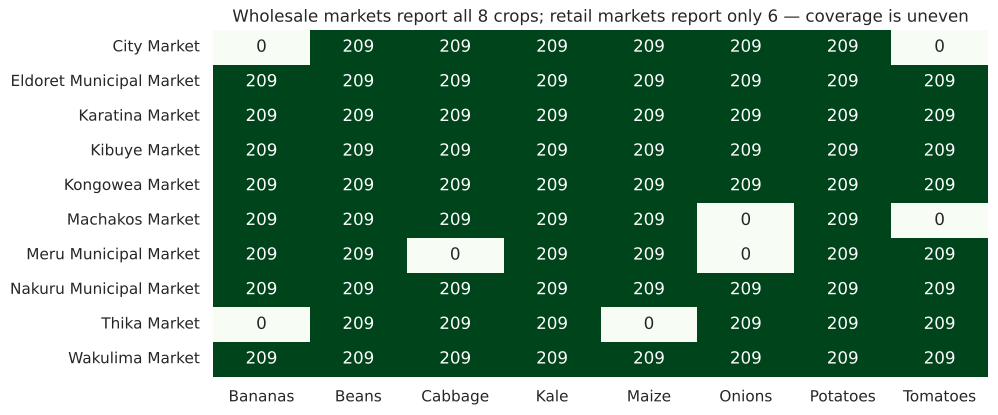

**Coverage.** 8 crops × 10 markets, **15,048** unique records, 2021-01-04 → 2024-12-30 (209 weekly dates). Each market-crop series should have one row per week.

In [5]:
# Coverage: which markets trade which crops? (computed on the deduplicated raw table; crops/markets are not damaged)
cov = pd.crosstab(prices_raw.drop_duplicates("record_id")["market"], prices_raw.drop_duplicates("record_id")["crop"])
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(cov, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax)
ax.set_title("Wholesale markets report all 8 crops; retail markets report only 6; coverage is uneven")
ax.set_xlabel(""); ax.set_ylabel("")
plt.show()
d_ = prices_raw.drop_duplicates("record_id")
md(f"**Coverage.** {d_['crop'].nunique()} crops × {d_['market'].nunique()} markets, **{len(d_):,}** unique records, "
   f"{pd.to_datetime(d_['date']).min().date()} → {pd.to_datetime(d_['date']).max().date()} "
   f"({pd.to_datetime(d_['date']).nunique()} weekly dates). Each market-crop series should have one row per week.")

**🧾 So what?** Five related tables. The price table is the heart (≈15k weekly observations, 72 market–crop series); production is annual and county-level; weather is monthly and county-level; markets and counties are small reference tables.
Because the grains differ (weekly / monthly / annual), every merge must first bring tables to a common grain.

---
# 2 · Data-quality assessment & cleaning

### 2.1 Audit: every dimension, with counts

In [6]:
p = prices_raw
valid_counties = set(counties["county"])
dedup = p.drop_duplicates(subset="record_id").copy()

# plausibility: compare each price to the median of its own crop-market series (AFTER fixing units, on a scratch copy)
scratch = dedup.copy()
bag = scratch["price_unit"] == "KES/90kg bag"
scratch.loc[bag, "price_kes_per_kg"] = scratch.loc[bag, "price_kes_per_kg"] / 90
ratio = scratch["price_kes_per_kg"] / scratch.groupby(["crop", "market"])["price_kes_per_kg"].transform("median")
n_outliers = int(((ratio > 3) | (ratio < 1 / 3)).sum() - (scratch["price_kes_per_kg"] <= 0).sum())   # zeros are counted under 'validity'

miss_by_market = dedup["price_kes_per_kg"].isna().groupby(dedup["market"]).mean() * 100
issues = pd.DataFrame([
    ("Uniqueness",   "exact duplicate rows",                         int(p.duplicated().sum()),
     "same record_id and values twice", "drop, keep first"),
    ("Consistency",  "county spelling/case/whitespace variants",     int((~dedup["county"].isin(valid_counties)).sum()),
     f"{dedup['county'].nunique()} labels for {len(valid_counties)} counties", "strip, hyphen→space, title-case"),
    ("Consistency",  "price reported per 90 kg bag, labelled per kg", int((dedup["price_unit"] != "KES/kg").sum()),
     "price_unit has a second value; maize prices ≈ 90× too high", "divide by 90, set unit = KES/kg"),
    ("Validity",     "price ≤ 0",                                    int((dedup["price_kes_per_kg"] <= 0).sum()),
     "impossible price", "set to missing, impute, flag"),
    ("Validity",     "negative volume",                              int((dedup["volume_kg"] < 0).sum()),
     "impossible quantity", "set to missing, impute"),
    ("Plausibility", "price >3× or <⅓ of its series median (decimal slips)", n_outliers,
     "ratio to crop–market median after unit fix", "set to missing, impute, flag"),
    ("Completeness", "missing price",                                int(dedup["price_kes_per_kg"].isna().sum()),
     f"not random: worst market {miss_by_market.idxmax()} ({miss_by_market.max():.1f}%) vs best {miss_by_market.min():.1f}%", "interpolate in time + flag"),
    ("Completeness", "missing volume",                               int(dedup["volume_kg"].isna().sum()),
     "gaps in traded quantity", "series median + flag"),
    ("Integrity",    "production rows whose county is not in `counties`", int((~production_raw["county"].isin(valid_counties)).sum()),
     "'Uasin-Gishu' vs 'Uasin Gishu'", "normalise hyphen"),
    ("Completeness", "production rows missing area_ha",              int(production_raw["area_ha"].isna().sum()),
     "gaps in area", "leave missing; do not use area-based ratios without care"),
], columns=["dimension", "issue", "rows_affected", "evidence", "decision"])
issues

,dimension,issue,rows_affected,evidence,decision
0,Uniqueness,exact duplicate rows,45,same record_id and values twice,"drop, keep first"
1,Consistency,county spelling/case/whitespace variants,609,46 labels for 9 counties,"strip, hyphen→space, title-case"
2,Consistency,"price reported per 90 kg bag, labelled per kg",60,price_unit has a second value; maize prices ≈ ...,"divide by 90, set unit = KES/kg"
3,Validity,price ≤ 0,6,impossible price,"set to missing, impute, flag"
4,Validity,negative volume,5,impossible quantity,"set to missing, impute"
5,Plausibility,price >3× or <⅓ of its series median (decimal ...,32,ratio to crop–market median after unit fix,"set to missing, impute, flag"
6,Completeness,missing price,351,not random: worst market Kongowea Market (6.3%...,interpolate in time + flag
7,Completeness,missing volume,406,gaps in traded quantity,series median + flag
8,Integrity,production rows whose county is not in `counties`,4,'Uasin-Gishu' vs 'Uasin Gishu',normalise hyphen
9,Completeness,production rows missing area_ha,7,gaps in area,leave missing; do not use area-based ratios wi...


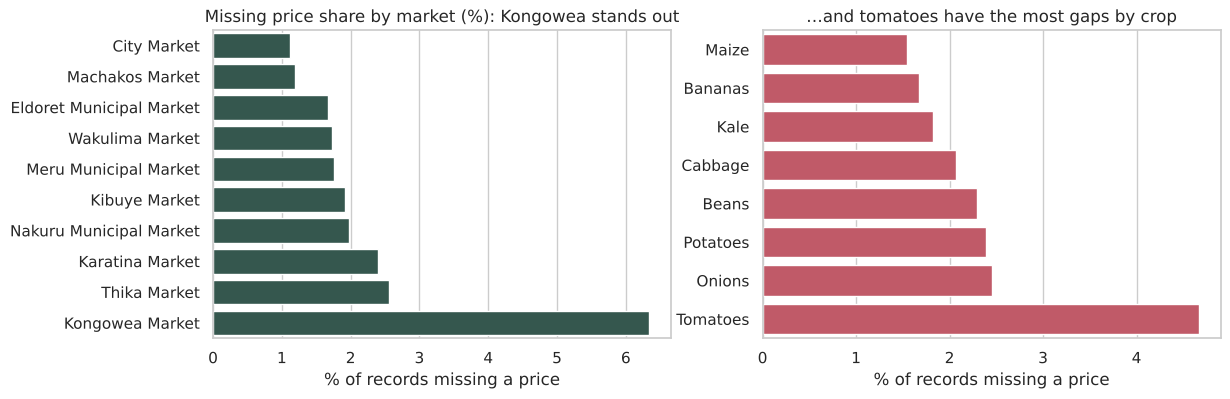

In [7]:
# Is the missingness random? (it matters: dropping rows would bias Mombasa and tomatoes)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=miss_by_market.sort_values().values, y=miss_by_market.sort_values().index, color="#2F5D50", ax=axes[0])
axes[0].set_title("Missing price share by market (%): Kongowea stands out"); axes[0].set_xlabel("% of records missing a price"); axes[0].set_ylabel("")
mc = (dedup["price_kes_per_kg"].isna().groupby(dedup["crop"]).mean() * 100).sort_values()
sns.barplot(x=mc.values, y=mc.index, color="#d1495b", ax=axes[1])
axes[1].set_title("…and tomatoes have the most gaps by crop"); axes[1].set_xlabel("% of records missing a price"); axes[1].set_ylabel("")
plt.show()

In [8]:
# Date continuity: is every weekly series complete, and are all dates Mondays?
dd = dedup.assign(date=pd.to_datetime(dedup["date"]))
per_series = dd.groupby(["crop", "market"])["date"].agg(["count", "min", "max", "nunique"])
print("all dates are Mondays:", bool((dd["date"].dt.dayofweek == 0).all()))
print("weeks per series: min / max:", per_series["count"].min(), "/", per_series["count"].max(), "  (expected", dd["date"].nunique(), ")")
print("series with a missing week:", int((per_series["count"] < dd["date"].nunique()).sum()))

all dates are Mondays: True
weeks per series: min / max: 209 / 209   (expected 209 )
series with a missing week: 0


### 2.2 Cleaning pipeline (order matters: duplicates → spelling → types → **units** → impossible/outlier → gaps)

In [9]:
def clean_prices(raw):
    """Raw market-price export -> analysis-ready table. Each step is one of the decisions in the issues table."""
    d = raw.drop_duplicates(subset="record_id").copy()                                     # 1 duplicates
    d["county"] = d["county"].str.strip().str.replace("-", " ", regex=False).str.title()   # 2 spelling
    d["date"] = pd.to_datetime(d["date"]); d["recorded_at"] = pd.to_datetime(d["recorded_at"])  # 3 types

    bag = d["price_unit"] == "KES/90kg bag"                                                # 4 units BEFORE outliers
    d.loc[bag, "price_kes_per_kg"] = d.loc[bag, "price_kes_per_kg"] / 90
    d["unit_converted"] = bag
    d["price_unit"] = "KES/kg"

    key = ["crop", "market"]
    ratio = d["price_kes_per_kg"] / d.groupby(key)["price_kes_per_kg"].transform("median") # 5 impossible + decimal slips
    bad = (d["price_kes_per_kg"] <= 0) | (ratio > 3) | (ratio < 1 / 3)
    d["price_was_invalid"] = bad
    d.loc[bad, "price_kes_per_kg"] = np.nan
    d.loc[d["volume_kg"] < 0, "volume_kg"] = np.nan

    d["price_imputed"] = d["price_kes_per_kg"].isna()                                      # 6 gaps: flag, then fill
    d["volume_imputed"] = d["volume_kg"].isna()
    d = d.sort_values(key + ["date"])
    d["price_kes_per_kg"] = d.groupby(key)["price_kes_per_kg"].transform(lambda s: s.interpolate(limit_direction="both"))
    d["volume_kg"] = d["volume_kg"].fillna(d.groupby(key)["volume_kg"].transform("median"))
    return d.reset_index(drop=True)


prices = clean_prices(prices_raw)
production = production_raw.copy()
production["county"] = production["county"].str.replace("-", " ", regex=False)
print(f"prices: {prices_raw.shape} -> {prices.shape}")

prices: (15093, 9) -> (15048, 13)


In [10]:
# Quality gates
assert prices["record_id"].is_unique
assert set(prices["county"]) == set(counties["county"]) & set(prices["county"]) and prices["county"].nunique() == 9
assert prices["price_unit"].eq("KES/kg").all()
assert prices["price_kes_per_kg"].between(10, 300).all()
assert (prices["volume_kg"] > 0).all()
assert prices[["price_kes_per_kg", "volume_kg"]].notna().all().all()
assert production["county"].isin(counties["county"]).all()
print("✅ All quality gates passed")

lost = len(prices_raw) - len(prices)
md(f"**What the cleaning did:** removed **{lost}** duplicate rows; converted **{int(prices['unit_converted'].sum())}** bag-priced rows; "
   f"set **{int(prices['price_was_invalid'].sum())}** invalid prices to missing; imputed in total **{int(prices['price_imputed'].sum())}** prices "
   f"(**{prices['price_imputed'].mean()*100:.1f}%** of rows) and **{int(prices['volume_imputed'].sum())}** volumes. No rows were dropped for being 'inconvenient'.")

✅ All quality gates passed


**What the cleaning did:** removed **45** duplicate rows; converted **60** bag-priced rows; set **38** invalid prices to missing; imputed in total **389** prices (**2.6%** of rows) and **411** volumes. No rows were dropped for being 'inconvenient'.

### 📒 Decision log

| Problem | Decision | Why |
|---|---|---|
| Exact duplicates | Drop (key: `record_id`) | Identical copies add no information; safe |
| County spelling | Normalise to the 9 valid names | Otherwise `groupby` splits one county into many |
| Bag-priced maize | **Convert** ÷90 rather than drop | The *information is good*, only the unit is wrong; dropping would bias maize in the two markets affected |
| Impossible values & decimal slips | **Set to missing → impute → flag** | We know the value is wrong but not what it should be; correcting by ×10/÷10 would "invent" certainty |
| Missing price | **Linear interpolation within each series** + `price_imputed` flag | Prices are highly autocorrelated; neighbours are the best predictors (Lesson 4 showed it beats the global mean by ~10×) |
| Missing volume | Series median + flag | Volume is noisier and not autocorrelated enough to interpolate |
| Production key mismatch | Normalise `Uasin-Gishu` | Otherwise a whole county-year silently drops out of merges |
| Missing `area_ha` | Leave as is | Imputing area would corrupt yield calculations; not needed for our questions |

**🧾 So what?** About 2.6% of prices needed repair; the dominant risks were the **90× unit mix-up** (would have wrecked Eldoret/Nakuru maize statistics) and **non-random gaps** (Mombasa, tomatoes). All repairs are flagged, so later analysis can exclude or test them.

---
# 3 · Descriptive statistics

In [11]:
mk = markets[["market", "type", "location_lat", "location_lon"]].rename(columns={"type": "market_type"})
prices = prices.merge(mk, on="market", how="left", validate="many_to_one")
prices["year"] = prices["date"].dt.year; prices["month"] = prices["date"].dt.month
assert prices["market_type"].notna().all()

by_crop = prices.groupby("crop").agg(
    n=("record_id", "count"), mean=("price_kes_per_kg", "mean"), median=("price_kes_per_kg", "median"),
    std=("price_kes_per_kg", "std"), min=("price_kes_per_kg", "min"), max=("price_kes_per_kg", "max")).round(1)
by_crop["cv"] = (by_crop["std"] / by_crop["mean"]).round(3)
by_crop["skew"] = prices.groupby("crop")["price_kes_per_kg"].skew().round(2)
by_crop.sort_values("mean", ascending=False)

,n,mean,median,std,min,max,cv,skew
crop,,,,,,,,
Beans,2090,155.3,154.5,19.0,108.5,213.7,0.122,0.13
Onions,1672,86.1,84.8,12.4,53.4,130.1,0.144,0.45
Tomatoes,1672,77.3,75.7,15.1,38.9,138.1,0.195,0.43
Maize,1881,63.4,63.0,11.1,38.0,91.6,0.175,0.21
Bananas,1672,49.5,49.3,5.8,35.4,69.2,0.117,0.36
Potatoes,2090,47.1,47.0,7.2,29.1,70.8,0.153,0.34
Kale,2090,38.7,38.8,5.6,23.8,58.2,0.145,0.13
Cabbage,1881,31.2,30.9,4.5,20.5,46.6,0.144,0.28


In [12]:
yearly = prices.pivot_table(index="crop", columns="year", values="price_kes_per_kg", aggfunc="mean").round(1)
yearly["change 2021→2024 %"] = ((yearly[2024] / yearly[2021] - 1) * 100).round(1)
yearly.sort_values("change 2021→2024 %", ascending=False)

year,2021,2022,2023,2024,change 2021→2024 %
crop,,,,,
Bananas,44.5,47.6,50.5,55.1,23.8
Maize,52.3,67.3,69.4,64.6,23.5
Tomatoes,69.2,76.0,78.6,85.2,23.1
Onions,77.1,83.7,88.4,94.8,23.0
Kale,34.9,38.4,38.9,42.6,22.1
Cabbage,28.3,30.8,31.3,34.5,21.9
Beans,137.1,154.1,162.9,166.9,21.7
Potatoes,41.7,47.0,49.0,50.7,21.6


In [13]:
rw = prices.pivot_table(index="crop", columns="market_type", values="price_kes_per_kg", aggfunc="mean")
rw["retail premium %"] = ((rw["retail"] / rw["wholesale"] - 1) * 100).round(1)
rw.round(1).sort_values("retail premium %", ascending=False)

market_type,retail,wholesale,retail premium %
crop,,,
Tomatoes,85.7,74.5,15.1
Onions,95.3,83.0,14.9
Maize,68.8,60.7,13.5
Beans,167.1,147.4,13.3
Cabbage,33.9,29.9,13.3
Bananas,54.0,47.9,12.7
Potatoes,50.4,44.9,12.2
Kale,41.4,37.0,12.0


In [14]:
vol = prices.groupby("crop")["volume_kg"].agg(total_tonnes=lambda s: s.sum() / 1000, typical_weekly_t=lambda s: s.median() / 1000, skew="skew").round(2)
display(vol.sort_values("total_tonnes", ascending=False))

mz_rank = prices[prices["crop"] == "Maize"].groupby("county")["price_kes_per_kg"].mean().sort_values().round(1)
md(f"**Maize by county (mean KES/kg).** Cheapest: **{mz_rank.index[0]}** ({mz_rank.iloc[0]}); dearest: **{mz_rank.index[-1]}** ({mz_rank.iloc[-1]}): a gap of "
   f"**{(mz_rank.iloc[-1]/mz_rank.iloc[0]-1)*100:.0f}%**.")

,total_tonnes,typical_weekly_t,skew
crop,,,
Maize,80185.07,39.94,0.90
Potatoes,65152.90,29.23,0.86
Cabbage,44928.10,22.47,0.93
Kale,39171.92,17.55,0.95
Tomatoes,37728.82,21.44,1.12
Beans,32391.22,14.67,0.95
Bananas,31021.66,17.76,0.84
Onions,26225.12,14.93,0.97


**Maize by county (mean KES/kg).** Cheapest: **Uasin Gishu** (55.4); dearest: **Machakos** (68.6): a gap of **24%**.

**🧾 So what?** Price levels differ massively by crop (beans ≈ 5× cabbage), so **never average across crops**. CV (not std) is the fair volatility measure: tomatoes are the most volatile (CV ≈ 0.19) and bananas and beans the steadiest (≈ 0.12).
Every crop is dearer in 2024 than in 2021 (+22% to +24%), with a retail premium of 12–15%. Price distributions are only mildly right-skewed (skew 0.1–0.5), so mean and median agree closely.

---
# 4 · Visualisations
### 4.1 Distributions by crop

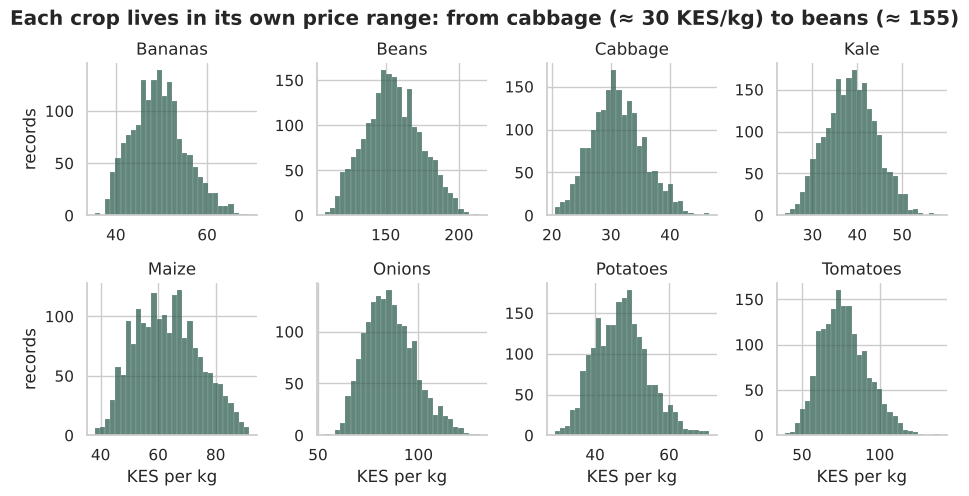

In [15]:
g = sns.displot(data=prices, x="price_kes_per_kg", col="crop", col_wrap=4, bins=30, height=2.4, color="#2F5D50", common_bins=False, facet_kws=dict(sharex=False, sharey=False))
g.set_titles("{col_name}"); g.set_axis_labels("KES per kg", "records")
g.figure.suptitle("Each crop lives in its own price range: from cabbage (≈ 30 KES/kg) to beans (≈ 155)", y=1.03, fontweight="bold")
plt.show()

### 4.2 Over time: price index (2021 = 100) with the drought shaded

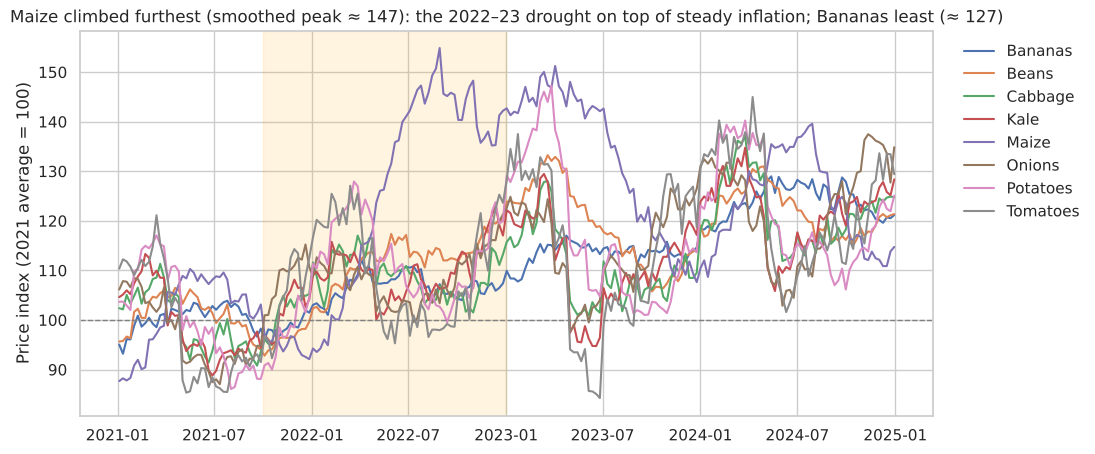

In [16]:
d = prices.copy()
base = d[d["year"] == 2021].groupby("crop")["price_kes_per_kg"].mean()
d["index"] = d["price_kes_per_kg"] / d["crop"].map(base) * 100
nat = d.groupby(["crop", "date"])["index"].mean().unstack(0)             # weekly national index per crop
peak = nat.rolling(13).mean().max().sort_values(ascending=False)         # peak of the 13-week smoothed index (robust to one-off spikes)
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=d, x="date", y="index", hue="crop", errorbar=None, ax=ax)
ax.axvspan(pd.Timestamp("2021-10-01"), pd.Timestamp("2022-12-31"), color="orange", alpha=0.12)
ax.axhline(100, color="grey", ls="--", lw=1)
ax.set_title(f"{peak.index[0]} climbed furthest (smoothed peak ≈ {peak.iloc[0]:.0f}): the 2022–23 drought on top of steady inflation; {peak.index[-1]} least (≈ {peak.iloc[-1]:.0f})")
ax.set_ylabel("Price index (2021 average = 100)"); ax.set_xlabel("")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.show()

### 4.3 Seasonality: detrended heatmap

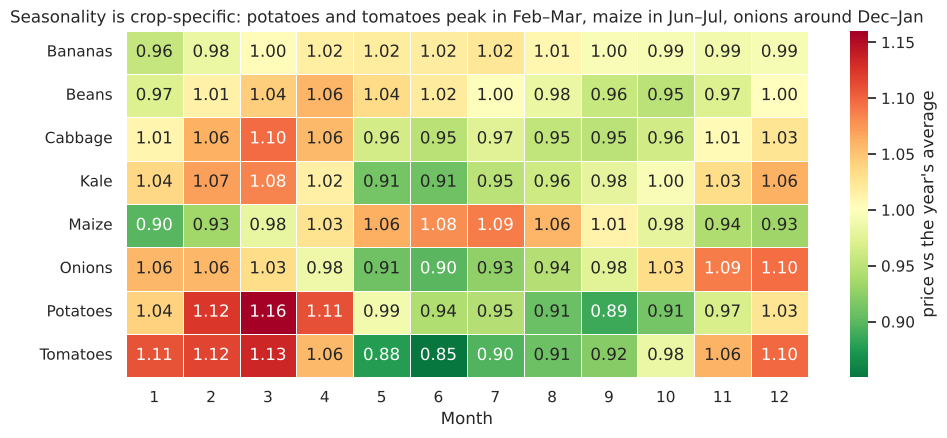

,dearest month,cheapest month,swing %
crop,,,
Bananas,7,1,7.0
Beans,4,10,11.0
Cabbage,3,6,16.0
Kale,3,6,19.0
Maize,7,1,21.0
Onions,12,6,22.0
Potatoes,3,9,31.0
Tomatoes,3,6,33.0


In [17]:
s = prices.copy()
s["relative_price"] = s["price_kes_per_kg"] / s.groupby(["crop", "market", "year"])["price_kes_per_kg"].transform("mean")
season = s.pivot_table(index="crop", columns="month", values="relative_price", aggfunc="mean")
peak_month = season.idxmax(axis=1); trough_month = season.idxmin(axis=1)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(season, cmap="RdYlGn_r", center=1, annot=True, fmt=".2f", linewidths=0.4, cbar_kws=dict(label="price vs the year's average"), ax=ax)
ax.set_title("Seasonality is crop-specific: potatoes and tomatoes peak in Feb–Mar, maize in Jun–Jul, onions around Dec–Jan")
ax.set_xlabel("Month"); ax.set_ylabel("")
plt.show()
display(pd.DataFrame({"dearest month": peak_month, "cheapest month": trough_month, "swing %": ((season.max(axis=1) / season.min(axis=1) - 1) * 100).round(0)}))

### 4.4 Markets compared (maize)

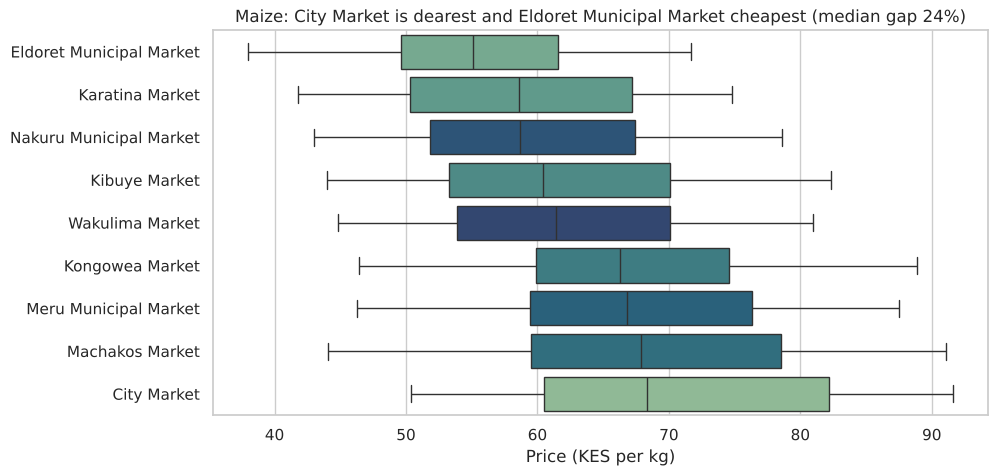

In [18]:
mz = prices[prices["crop"] == "Maize"]
order = mz.groupby("market")["price_kes_per_kg"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=mz, y="market", x="price_kes_per_kg", order=order, hue="market", legend=False, palette="crest", ax=ax)
med = mz.groupby("market")["price_kes_per_kg"].median()
ax.set_title(f"Maize: {med.idxmax()} is dearest and {med.idxmin()} cheapest (median gap {(med.max()/med.min()-1)*100:.0f}%)")
ax.set_xlabel("Price (KES per kg)"); ax.set_ylabel("")
plt.show()

### 4.5 Price vs volume: within each crop

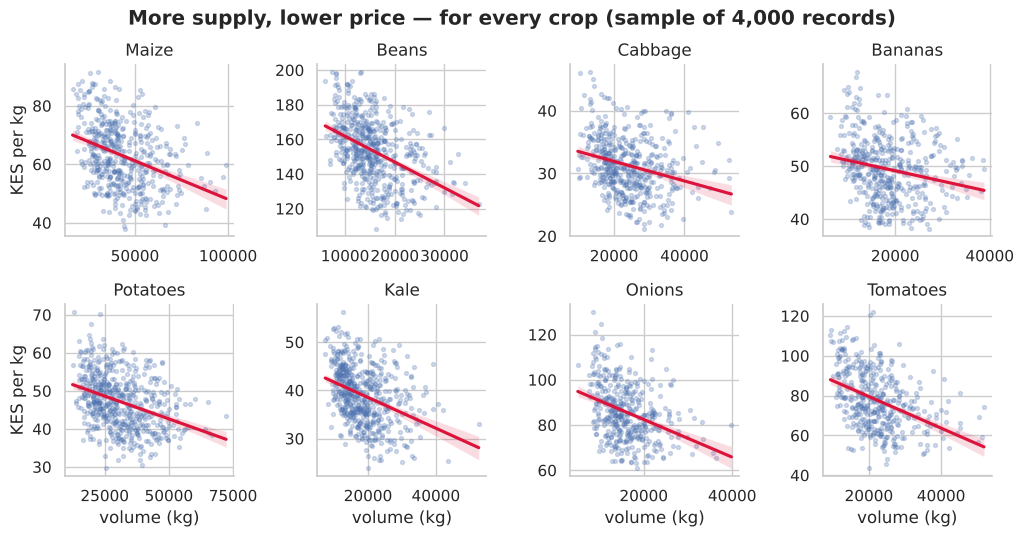

In [19]:
g = sns.lmplot(data=prices.sample(4000, random_state=1), x="volume_kg", y="price_kes_per_kg", col="crop", col_wrap=4, height=2.6,
               scatter_kws=dict(alpha=0.25, s=8), line_kws=dict(color="crimson"), facet_kws=dict(sharex=False, sharey=False))
g.set_titles("{col_name}"); g.set_axis_labels("volume (kg)", "KES per kg")
g.figure.suptitle("More supply, lower price: for every crop (sample of 4,000 records)", y=1.03, fontweight="bold")
plt.show()

### 4.6 Where is production concentrated?

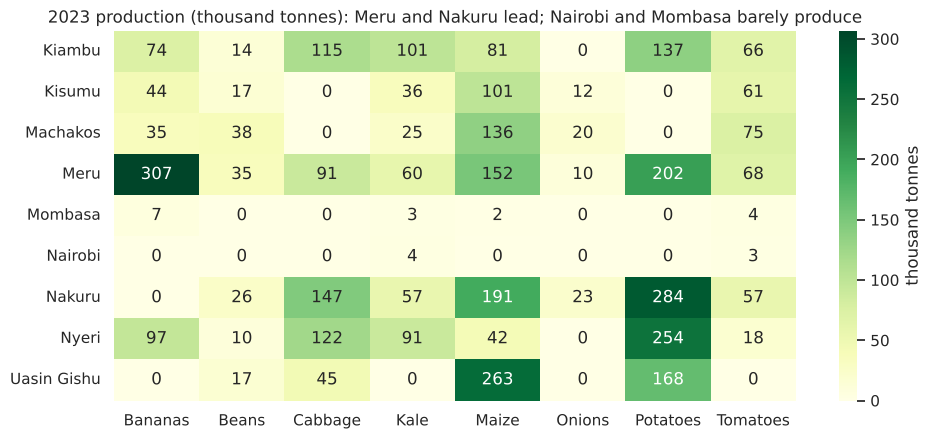

In [20]:
p23 = production[production["year"] == 2023].pivot_table(index="county", columns="crop", values="production_tonnes", aggfunc="sum").fillna(0) / 1000
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.heatmap(p23, annot=True, fmt=".0f", cmap="YlGn", cbar_kws=dict(label="thousand tonnes"), ax=ax)
top = p23.sum(axis=1).sort_values(ascending=False)
ax.set_title(f"2023 production (thousand tonnes): {top.index[0]} and {top.index[1]} lead; Nairobi and Mombasa barely produce")
ax.set_xlabel(""); ax.set_ylabel("")
plt.show()

**🧾 So what?** Three things matter most: (1) **maize** jumped far more than other crops in 2022 (+29% vs +7–13% for the rest, see the yearly table): the drought signature; (2) **seasonality is strong and crop-specific**, so a model needs month information; (3) **supply (volume) and price move in opposite directions** within every crop.

---
# 5 · Correlation analysis: quantify, then challenge

### 5.1 Price vs volume: pooled vs within-series

**Pooled correlation (all rows): -0.30.** Mean *within-series* correlation: **-0.35** (range -0.57 to -0.14 across 72 series).

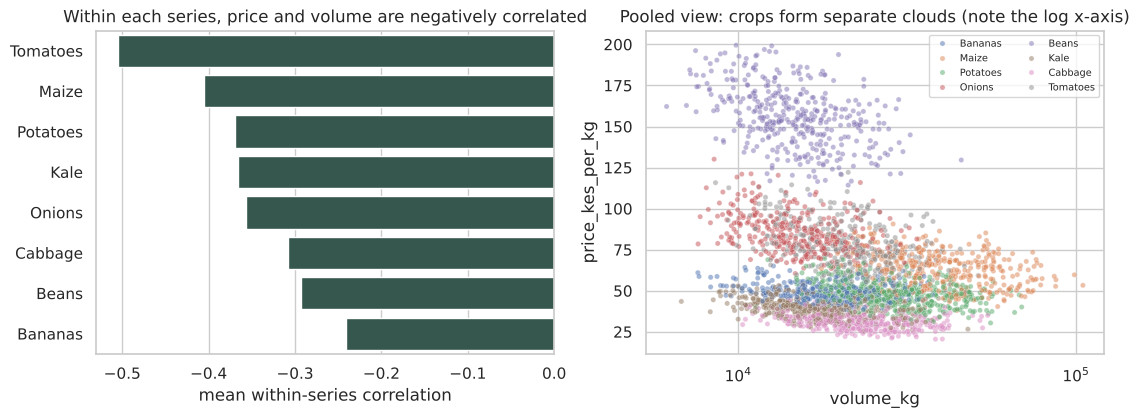

In [21]:
pooled = prices["price_kes_per_kg"].corr(prices["volume_kg"])
within = (prices.groupby(["crop", "market"])[["price_kes_per_kg", "volume_kg"]]
          .apply(lambda g: g["price_kes_per_kg"].corr(g["volume_kg"])).rename("r").reset_index())
by_crop_r = within.groupby("crop")["r"].mean().sort_values()
md(f"**Pooled correlation (all rows): {pooled:.2f}.** Mean *within-series* correlation: **{within['r'].mean():.2f}** "
   f"(range {within['r'].min():.2f} to {within['r'].max():.2f} across {len(within)} series).")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.barplot(x=by_crop_r.values, y=by_crop_r.index, color="#2F5D50", ax=axes[0])
axes[0].set_title("Within each series, price and volume are negatively correlated"); axes[0].set_xlabel("mean within-series correlation"); axes[0].set_ylabel("")
sns.scatterplot(data=prices.sample(3000, random_state=0), x="volume_kg", y="price_kes_per_kg", hue="crop", alpha=0.5, s=14, ax=axes[1])
axes[1].set_title("Pooled view: crops form separate clouds (note the log x-axis)"); axes[1].set_xscale("log")
axes[1].legend(fontsize=7, ncol=2)
plt.show()

**Reading it.** The relationship is **negative in every one of the 72 series** (supply up → price down), and the pooled figure (≈ −0.30) happens to land close to the within-series average (≈ −0.35). That agreement is partly luck: the pooled scatter is a mixture of separate crop clouds, so the pooled number could easily have been misleading. **Lesson: always compute the within-group version too**: here it confirms the pooled one and shows the effect is consistent, not driven by a few series.

### 5.2 Price vs lagged rainfall (detrended, per crop)

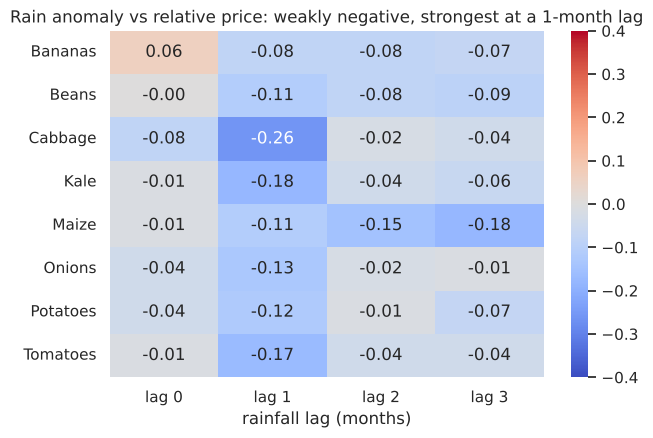

,lag 0,lag 1,lag 2,lag 3
crop,,,,
Bananas,0.06,-0.08,-0.08,-0.07
Beans,-0.00,-0.11,-0.08,-0.09
Cabbage,-0.08,-0.26,-0.02,-0.04
Kale,-0.01,-0.18,-0.04,-0.06
Maize,-0.01,-0.11,-0.15,-0.18
Onions,-0.04,-0.13,-0.02,-0.01
Potatoes,-0.04,-0.12,-0.01,-0.07
Tomatoes,-0.01,-0.17,-0.04,-0.04


In [22]:
w = weather.sort_values(["county", "year", "month"]).copy()
for k in [1, 2, 3]:
    w[f"rain_lag{k}"] = w.groupby("county")["rainfall_mm"].shift(k)
w = w.rename(columns={"rainfall_mm": "rain_lag0"})

monthly = (prices.groupby(["crop", "county", "year", "month"], as_index=False)["price_kes_per_kg"].mean())
monthly["rel_price"] = monthly["price_kes_per_kg"] / monthly.groupby(["crop", "county", "year"])["price_kes_per_kg"].transform("mean")
panel = monthly.merge(w, on=["county", "year", "month"], how="left", validate="many_to_one")
# remove each county's seasonal rainfall norm too: use rainfall relative to that county's average for the calendar month
for k in range(4):
    c = f"rain_lag{k}"
    panel[c + "_anom"] = panel[c] / panel.groupby(["county", "month"])[c].transform("mean")

lagtab = pd.DataFrame({f"lag {k}": panel.groupby("crop").apply(lambda g, k=k: g["rel_price"].corr(g[f"rain_lag{k}_anom"]), include_groups=False) for k in range(4)}).round(2)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(lagtab, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.4, vmax=0.4, ax=ax)
ax.set_title("Rain anomaly vs relative price: weakly negative, strongest at a 1-month lag")
ax.set_ylabel(""); ax.set_xlabel("rainfall lag (months)")
plt.show()
lagtab

**Reading it.** After removing inflation (relative price) and each county's normal rainy-season pattern (rain *anomaly*), almost every crop shows a **negative** correlation with rain (wetter than usual, somewhat lower prices) and the strongest value is at a **1-month lag** for **cabbage (≈ −0.26), kale and tomatoes (≈ −0.17/−0.18)**. But every |r| is small (≤ 0.26), so rain explains only a few percent of price variation. The raw rain-vs-price correlation we saw in Lesson 5 (≈ 0.05) hid even this because *seasonality* and *county differences* swamped it.
**Hypothesis:** *wetter-than-usual months modestly lower leafy-vegetable prices about a month later.* It is a **weak, plausible** signal worth including as a lagged feature: not a strong driver.

### 5.3 Crop vs crop: levels vs changes

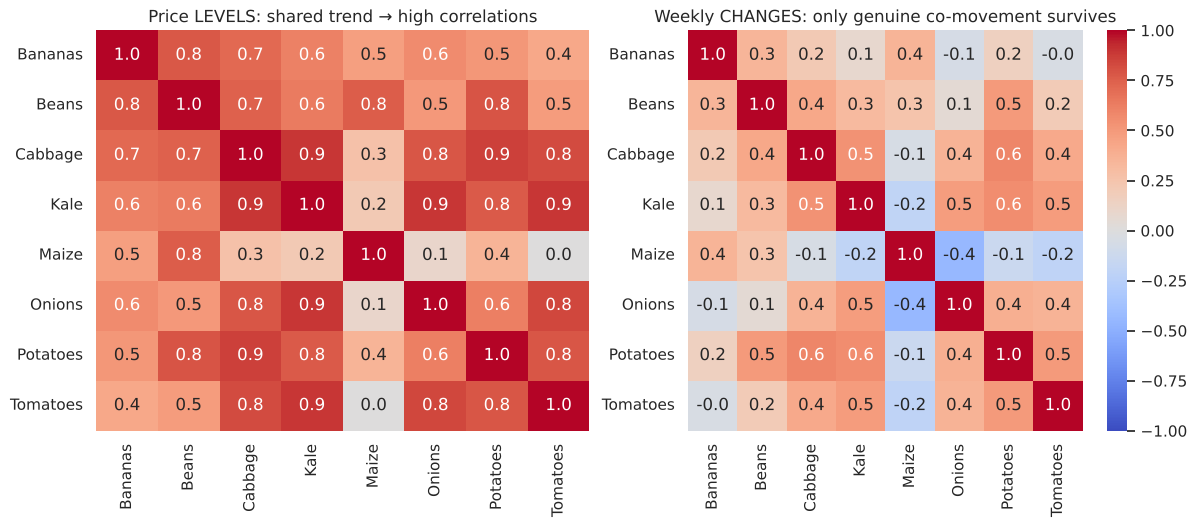

**Average pairwise correlation: 0.61 in levels vs 0.23 in weekly changes.**

In [23]:
wide = prices.pivot_table(index="date", columns="crop", values="price_kes_per_kg", aggfunc="mean")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.heatmap(wide.corr(), annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1, center=0, cbar=False, ax=axes[0]); axes[0].set_title("Price LEVELS: shared trend → high correlations")
sns.heatmap(wide.pct_change().dropna().corr(), annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=axes[1]); axes[1].set_title("Weekly CHANGES: only genuine co-movement survives")
for a in axes: a.set_xlabel(""); a.set_ylabel("")
plt.show()
lv = wide.corr().where(np.triu(np.ones((8, 8), bool), 1)).stack().mean()
ch = wide.pct_change().dropna().corr().where(np.triu(np.ones((8, 8), bool), 1)).stack().mean()
md(f"**Average pairwise correlation: {lv:.2f} in levels vs {ch:.2f} in weekly changes.**")

### 5.4 Production vs price across counties

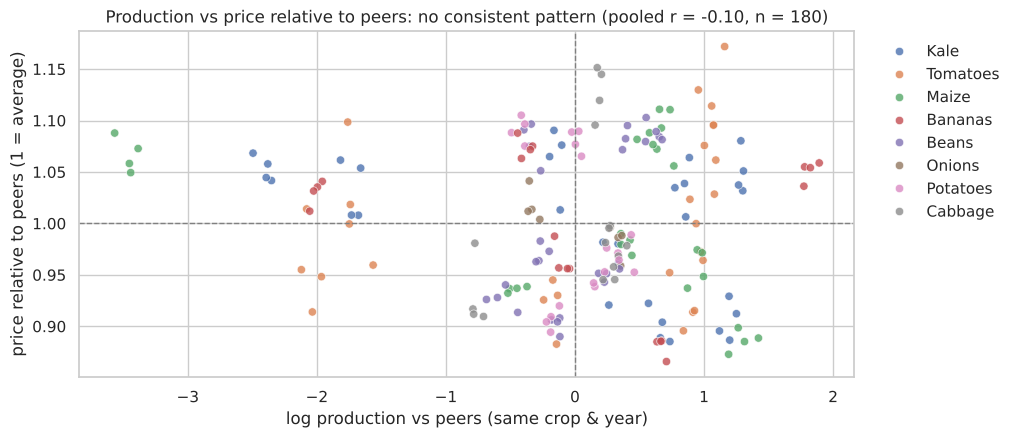

crop
Bananas    -0.16
Beans       0.52
Cabbage     0.43
Kale       -0.43
Maize      -0.36
Onions     -0.82
Potatoes   -0.39
Tomatoes    0.28
dtype: float64

In [24]:
ann = prices.groupby(["county", "crop", "year"], as_index=False)["price_kes_per_kg"].mean()
pp = production.merge(ann, on=["county", "crop", "year"], how="inner", validate="one_to_one")
pp["rel_price"] = pp["price_kes_per_kg"] / pp.groupby(["crop", "year"])["price_kes_per_kg"].transform("mean")   # remove crop & year level
pp["log_prod"] = np.log(pp["production_tonnes"])
pp["rel_prod"] = pp["log_prod"] - pp.groupby(["crop", "year"])["log_prod"].transform("mean")
r_all = pp["rel_prod"].corr(pp["rel_price"])
r_by_crop = pp.groupby("crop")[["rel_prod", "rel_price"]].apply(lambda g: g["rel_prod"].corr(g["rel_price"]), include_groups=False).round(2)
fig, ax = plt.subplots()
sns.scatterplot(data=pp, x="rel_prod", y="rel_price", hue="crop", alpha=0.8, ax=ax)
ax.axhline(1, color="grey", ls="--", lw=1); ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_title(f"Production vs price relative to peers: no consistent pattern (pooled r = {r_all:.2f}, n = {len(pp)})")
ax.set_xlabel("log production vs peers (same crop & year)"); ax.set_ylabel("price relative to peers (1 = average)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.show()
r_by_crop

**Reading it.** After comparing each county with its *peers for the same crop and year*, the sign of the production–price relationship **changes by crop** (from strongly negative for onions to positive for beans). With only a handful of counties per crop (n ≈ 20–30 points each, from ~7 counties), such swings are what *noise* looks like, and **market type** (retail premium) and **distance to big cities** are uncontrolled confounders. Honest conclusion: **inconclusive**: we cannot claim that higher local production lowers local prices from these data.

**🧾 So what?** Of the four relationships: price–volume (within series) is **real and consistent**; rain → prices is **weak, lagged, and only visible after detrending**; crop–crop correlation in levels is **mostly a shared clock**; production–price is **inconclusive** (mixed signs, tiny samples).

---
# 6 · Observations, hypotheses & conclusions
### 6.1 Findings (every number computed)

In [25]:
yoy = prices.groupby("year")["price_kes_per_kg"].mean()
mz_y = prices[prices["crop"] == "Maize"].groupby("year")["price_kes_per_kg"].mean()
cvs = (prices.groupby("crop")["price_kes_per_kg"].std() / prices.groupby("crop")["price_kes_per_kg"].mean())
prem = (rw["retail"] / rw["wholesale"] - 1).mean() * 100
hi_idx = peak

md(f"""
1. **Maize inflation spike.** National maize averaged **{mz_y[2021]:.1f}** KES/kg in 2021, **{mz_y[2022]:.1f}** in 2022 (**+{(mz_y[2022]/mz_y[2021]-1)*100:.0f}%**), then **{mz_y[2024]:.1f}** in 2024.
2. **Maize rose furthest.** Peak of the 13-week smoothed price index (2021 = 100): {', '.join(f'{c} {v:.0f}' for c, v in hi_idx.head(3).items())}; lowest: {hi_idx.index[-1]} ({hi_idx.iloc[-1]:.0f}).
3. **Volatility ranking.** Most volatile crop by CV: **{cvs.idxmax()}** ({cvs.max():.2f}); steadiest: **{cvs.idxmin()}** ({cvs.min():.2f}).
4. **Retail premium.** Retail markets average **{prem:.0f}%** above wholesale for the same crop.
5. **Seasonality.** Detrended seasonal swing (dearest vs cheapest month) is largest for **{(season.max(axis=1)/season.min(axis=1)).idxmax()}** (**{((season.max(axis=1)/season.min(axis=1)).max()-1)*100:.0f}%**).
6. **Supply effect.** Within market–crop series, mean price–volume correlation is **{within['r'].mean():.2f}** (all {int((within['r']<0).sum())} of {len(within)} series negative); pooled: {pooled:.2f}.
7. **Data quality.** **{prices['price_imputed'].mean()*100:.1f}%** of prices had to be imputed; {int(prices['unit_converted'].sum())} rows had a unit mix-up that would have inflated maize statistics ~90× in those rows.
8. **Geography.** Maize is cheapest in **{mz_rank.index[0]}**, dearest in **{mz_rank.index[-1]}** ({(mz_rank.iloc[-1]/mz_rank.iloc[0]-1)*100:.0f}% gap).
""")


1. **Maize inflation spike.** National maize averaged **52.3** KES/kg in 2021, **67.3** in 2022 (**+29%**), then **64.6** in 2024.
2. **Maize rose furthest.** Peak of the 13-week smoothed price index (2021 = 100): Maize 147, Potatoes 138, Tomatoes 137; lowest: Bananas (127).
3. **Volatility ranking.** Most volatile crop by CV: **Tomatoes** (0.19); steadiest: **Bananas** (0.12).
4. **Retail premium.** Retail markets average **13%** above wholesale for the same crop.
5. **Seasonality.** Detrended seasonal swing (dearest vs cheapest month) is largest for **Tomatoes** (**33%**).
6. **Supply effect.** Within market–crop series, mean price–volume correlation is **-0.35** (all 72 of 72 series negative); pooled: -0.30.
7. **Data quality.** **2.6%** of prices had to be imputed; 60 rows had a unit mix-up that would have inflated maize statistics ~90× in those rows.
8. **Geography.** Maize is cheapest in **Uasin Gishu**, dearest in **Machakos** (24% gap).


### 6.2 Hypothesis table

| Observation | Hypothesis | How I would test it | ML implication |
|---|---|---|---|
| Maize had the largest 2022–23 rise (smoothed index peak) | Staple prices respond strongly to drought-driven supply shocks | Regress price index on lagged rainfall anomaly + county fixed effects | Regime shifts: don't train only on 'normal' years; add rainfall-anomaly features |
| Crop-specific seasonal peaks | Seasonality is harvest-cycle driven | Compare month effects across years (are they stable?) | Month (cyclical sin/cos) as a feature; seasonal-naive baseline |
| Price–volume r < 0 in every series (≈ −0.35 on average) | Supply pushes price down | Within-series regressions with crop/market fixed effects; check causal direction (do high prices also *reduce* volume?) | Lagged volume is a useful feature; fit crop-aware models |
| Weak negative price–rain-anomaly correlation, strongest at lag 1 (cabbage, kale, tomatoes ≈ −0.2) | Wet anomalies modestly raise leafy-vegetable supply | Distributed-lag regression on rain anomaly, county fixed effects | Lagged rain anomaly as a *weak* feature; expect small gains |
| Retail ≫ wholesale | Retail premium is a stable markup | Compare same crop–week across market types | `market_type` as a feature |
| Price levels of all crops correlate; changes mostly don't | Shared inflation/drought clock | Correlate de-trended series only | Never use another crop's *level* as a signal without detrending |
| Missing prices concentrated in Kongowea/tomatoes | Missingness is *not* random (reporting capacity) | Check by enumerator/week if available | Keep `price_imputed` flag; avoid dropping |

### 6.3 Limitations
* The data are **synthetic** and cover only **4 years** and **10 markets**: conclusions describe this dataset, not Kenya.
* Weekly price observations are single enumerator reports: **no sampling error estimate** is available.
* Drivers we **cannot see**: transport costs, fuel prices, imports/export policy, exchange rates, storage, farm-gate prices.
* Imputation (≈ 2.6% of prices) smooths real short-lived spikes; results on extreme weeks should be treated with care.
* County-level production has **few observations per crop** (≤ 8 counties × 4 years), so production–price conclusions are not reliable.

### 6.4 Answers to the brief
1. **What's in the data and can we trust it?** Five related tables; ~15k weekly records. Trustworthy *after* repairs: duplicates, a unit mix-up, spelling, impossible values and non-random gaps were found and handled (§2).
2. **What patterns?** Strong upward trend with a drought-driven bump in staples; crop-specific seasonality; retail premium; wide differences between counties (§3–4).
3. **What seems to drive prices?** **Supply** (volume) within each series (r ≈ −0.35), **season**, the **2022–23 drought** (largest for maize), a weak lagged **rain-anomaly** effect, and **market type/location**. What only *looks* like a driver: raw temperature/rain correlations, cross-crop level correlations (shared trend), and the production–price pattern (inconclusive) (§5).
4. **Is it ready for ML?** Yes, with preparation: see §7.

---
# 7 · ML-readiness
### 7.1 Candidate targets
* **A. Next-week price** per crop–market (regression): the core forecasting problem.
* **B. Price-spike label**: will price rise > 10% within 4 weeks? (classification; check class balance).
* **C. County production** (annual, tiny n): regression but very few rows; weak candidate.

We build features for **A**.

### 7.2 Features without leakage

In [26]:
f = prices.sort_values(["crop", "market", "date"]).copy()
g = f.groupby(["crop", "market"])
f["price_lag1"] = g["price_kes_per_kg"].shift(1)                      # last week            (known at prediction time)
f["price_lag4"] = g["price_kes_per_kg"].shift(4)
f["price_lag52"] = g["price_kes_per_kg"].shift(52)                    # same week last year  (seasonal naive)
f["price_ma4_prev"] = g["price_kes_per_kg"].transform(lambda s: s.shift(1).rolling(4).mean())   # shift FIRST: window excludes today
f["vol_lag1"] = g["volume_kg"].shift(1)
f["month_sin"] = np.sin(2 * np.pi * f["month"] / 12); f["month_cos"] = np.cos(2 * np.pi * f["month"] / 12)   # December is next to January
f = f.merge(w[["county", "year", "month", "rain_lag1", "rain_lag2"]], on=["county", "year", "month"], how="left", validate="many_to_one")
f["is_retail"] = (f["market_type"] == "retail").astype(int)

features = ["price_lag1", "price_lag4", "price_lag52", "price_ma4_prev", "vol_lag1", "month_sin", "month_cos", "rain_lag1", "rain_lag2", "is_retail", "crop", "county"]
target = "price_kes_per_kg"
model_df = f.dropna(subset=["price_lag1", "price_lag4", "price_ma4_prev", "vol_lag1", "rain_lag1", "rain_lag2"]).copy()
n_series = f.groupby(["crop", "market"]).ngroups
print(f"rows before dropping warm-up: {len(f):,} | usable: {len(model_df):,}  (≈{(len(f) - len(model_df)) / n_series:.0f} weeks lost per series: lag warm-up, and no rainfall lags before 2021-03)")
model_df[["date", "crop", "market", target] + features[:9]].head(4)

rows before dropping warm-up: 15,048 | usable: 14,472  (≈8 weeks lost per series: lag warm-up, and no rainfall lags before 2021-03)


,date,crop,market,price_kes_per_kg,price_lag1,price_lag4,price_lag52,price_ma4_prev,vol_lag1,month_sin,month_cos,rain_lag1,rain_lag2
8,2021-03-01,Bananas,Eldoret Municipal Market,40.9,39.1,39.9,NaN,39.250,18725.0,1.0,6.123234e-17,31.8,23.2
9,2021-03-08,Bananas,Eldoret Municipal Market,40.7,40.9,39.7,NaN,39.500,23800.0,1.0,6.123234e-17,31.8,23.2
10,2021-03-15,Bananas,Eldoret Municipal Market,40.6,40.7,38.3,NaN,39.750,19670.0,1.0,6.123234e-17,31.8,23.2
11,2021-03-22,Bananas,Eldoret Municipal Market,40.2,40.6,39.1,NaN,40.325,22850.0,1.0,6.123234e-17,31.8,23.2


| Feature group | Features | Leakage check |
|---|---|---|
| **Lags / rolling** | `price_lag1`, `price_lag4`, `price_lag52`, `price_ma4_prev` | ✅ all shifted ≥ 1 week; the rolling window excludes the current row |
| **Calendar** | `month_sin`, `month_cos` | ✅ known in advance; cyclic encoding keeps Dec next to Jan |
| **Weather** | `rain_lag1`, `rain_lag2` | ✅ lagged months only (**current-month rain may not be known at forecast time**) |
| **Supply** | `vol_lag1` | ✅ last week's volume; *this* week's volume would be leakage (it is simultaneous with the price) |
| **Static** | `is_retail`, `crop`, `county` | ✅ categorical → one-hot |
| ⛔ **Do NOT use** | `price_imputed`/`price_was_invalid` of the target row, any `shift(-k)`, `price_unit`, `record_id`, same-week volume, future-averaged stats | leakage / meaningless |

### 7.3 Chronological split and the naive baseline

In [27]:
train = model_df[model_df["date"] < "2024-01-01"]
test = model_df[model_df["date"] >= "2024-01-01"]
print(f"train: {train['date'].min().date()} → {train['date'].max().date()} ({len(train):,} rows)")
print(f"test : {test['date'].min().date()} → {test['date'].max().date()} ({len(test):,} rows)")

def scores(df, pred):
    err = (df[target] - pred).abs()
    return pd.Series({"MAE (KES/kg)": err.mean(), "MAPE %": (err / df[target]).mean() * 100})

base = pd.DataFrame({
    "naive: last week": scores(test, test["price_lag1"]),
    "naive: 4-wk average": scores(test, test["price_ma4_prev"]),
    "seasonal naive: 52 wks ago": scores(test.dropna(subset=["price_lag52"]), test.dropna(subset=["price_lag52"])["price_lag52"]),
}).round(2)
base

train: 2021-03-01 → 2023-12-25 (10,656 rows)
test : 2024-01-01 → 2024-12-30 (3,816 rows)


,naive: last week,naive: 4-wk average,seasonal naive: 52 wks ago
MAE (KES/kg),3.09,3.69,7.06
MAPE %,4.47,5.39,10.16


In [28]:
by_crop_err = (test.assign(abs_err=(test[target] - test["price_lag1"]).abs(), pct=lambda t: (t[target] - t["price_lag1"]).abs() / t[target] * 100)
               .groupby("crop")[["abs_err", "pct"]].mean().round(2).rename(columns={"abs_err": "MAE (KES/kg)", "pct": "MAPE %"}).sort_values("MAPE %"))
by_crop_err

,MAE (KES/kg),MAPE %
crop,,
Beans,4.39,2.64
Bananas,1.48,2.68
Maize,2.09,3.26
Onions,4.06,4.33
Potatoes,2.40,4.75
Cabbage,1.76,5.20
Kale,2.24,5.34
Tomatoes,6.62,7.77


**Reading it.** "Same as last week" is a **very strong baseline** (a few percent error), whereas the **seasonal-naive** forecast (same week last year) is far worse because the trend and the 2022–23 shock make last year's level a poor guide.
So any ML model must *beat last week's price*; realistic gains will come from **vegetables** (high weekly noise, rain-sensitive) rather than steady crops like bananas.

### 7.4 Preparation list and checklist

| Check | Status | Note |
|---|---|---|
| Target defined | ✅ | next-week price per crop–market |
| Leakage removed | ✅ | lags ≥ 1; no same-week volume; no imputation flags of the target row |
| Missing-value policy | ✅ | interpolation + flags (≈2.6% of prices imputed); lag warm-up rows dropped |
| Chronological split | ✅ | train 2021–2023, test 2024; **never shuffle** time series |
| Baseline to beat | ✅ | last-week naive (see table) |
| Encoding | ⚠️ to do | one-hot `crop`, `county`; or per-series models |
| Scaling | ⚠️ to do | needed for linear/NN/kNN models, not for tree models |
| Transformations | ⚠️ consider | model `log(price)` or the *percentage change* so crops with different price levels are comparable |
| Non-stationarity | ⚠️ note | the 2022–23 shock is a regime change; validate with rolling-origin backtests, not one split |
| Imputed rows | ⚠️ note | exclude imputed target rows from the *test* score, or report both |

**🧾 So what?** The data are ready for a first modelling pass: ~14k usable rows, leak-free lag/season/weather features, and a clear baseline. The honest expectation is *modest* improvement over "same as last week", most plausible for volatile, rain-sensitive vegetables.

---
## 🏁 End of reference solution

If your analysis found something this one missed: good. That is exactly how analysis gets better.